In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/raw/PJME_hourly.csv")

df = pd.read_csv(DATA_PATH)
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df = df.dropna(subset=["Datetime", "PJME_MW"])
df = df.sort_values("Datetime").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Date range:", df["Datetime"].min(), "to", df["Datetime"].max())

Dataset loaded successfully!
Rows: 145366
Date range: 2002-01-01 01:00:00 to 2018-08-03 00:00:00


In [2]:
analysis_df = df.copy()

# Previous 24 hours ka rolling median
analysis_df["Rolling_Median"] = (
    analysis_df["PJME_MW"]
    .shift(1)
    .rolling(window=24, min_periods=24)
    .median()
)

# Actual demand aur baseline ke beech difference
analysis_df["Deviation"] = (
    analysis_df["PJME_MW"] - analysis_df["Rolling_Median"]
)

# Robust scale: previous 24 hours ke absolute deviations ka median
analysis_df["Rolling_MAD"] = (
    analysis_df["Deviation"]
    .abs()
    .shift(1)
    .rolling(window=24, min_periods=24)
    .median()
)

# Zero MAD ko handle karo
scale = (1.4826 * analysis_df["Rolling_MAD"]).replace(0, np.nan)

analysis_df["Anomaly_Score"] = (
    analysis_df["Deviation"].abs() / scale
)

# Initial screening threshold
analysis_df["Potential_Anomaly"] = (
    analysis_df["Anomaly_Score"] > 3.5
)

print("Potential anomalies:",
      int(analysis_df["Potential_Anomaly"].sum()))

analysis_df[
    ["Datetime", "PJME_MW", "Rolling_Median",
     "Anomaly_Score", "Potential_Anomaly"]
].tail(10)

Potential anomalies: 5061


,Datetime,PJME_MW,Rolling_Median,Anomaly_Score,Potential_Anomaly
145356,2018-08-02 15:00:00,47154.0,41427.5,0.525399,False
145357,2018-08-02 16:00:00,46989.0,41427.5,0.555031,False
145358,2018-08-02 17:00:00,46816.0,41427.5,0.609073,False
145359,2018-08-02 18:00:00,46760.0,41427.5,0.637265,False
145360,2018-08-02 19:00:00,45641.0,41427.5,0.513709,False
145361,2018-08-02 20:00:00,44057.0,41427.5,0.325680,False
145362,2018-08-02 21:00:00,43256.0,41427.5,0.230073,False
145363,2018-08-02 22:00:00,41552.0,41427.5,0.016089,False
145364,2018-08-02 23:00:00,38500.0,41109.0,0.353629,False
145365,2018-08-03 00:00:00,35486.0,40727.0,0.710375,False


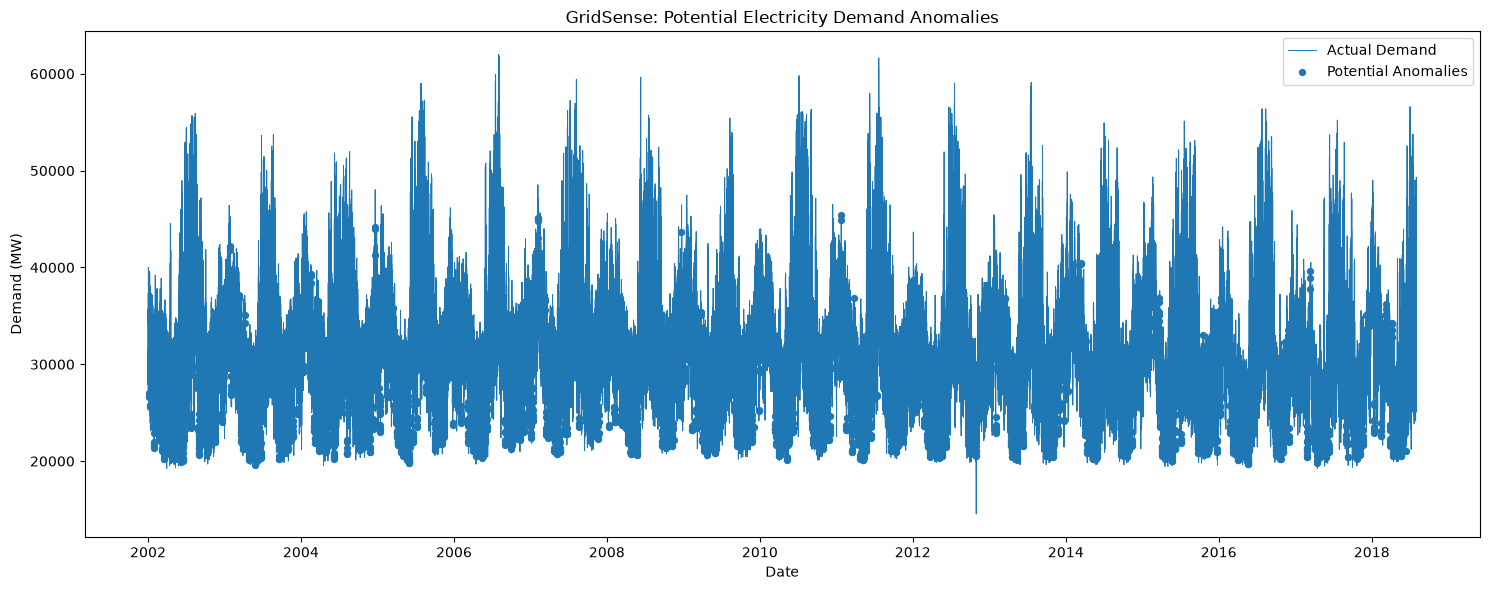

In [3]:
plt.figure(figsize=(15, 6))

plt.plot(
    analysis_df["Datetime"],
    analysis_df["PJME_MW"],
    label="Actual Demand",
    linewidth=0.7
)

anomalies = analysis_df[analysis_df["Potential_Anomaly"]]

plt.scatter(
    anomalies["Datetime"],
    anomalies["PJME_MW"],
    label="Potential Anomalies",
    s=18
)

plt.title("GridSense: Potential Electricity Demand Anomalies")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
analysis_df.nlargest(
    10, "Anomaly_Score"
)[
    ["Datetime", "PJME_MW", "Rolling_Median",
     "Deviation", "Anomaly_Score"]
]

,Datetime,PJME_MW,Rolling_Median,Deviation,Anomaly_Score
99315,2013-05-02 04:00:00,21172.0,28845.5,-7673.5,21.453699
99314,2013-05-02 03:00:00,21218.0,28845.5,-7627.5,21.325091
99313,2013-05-02 02:00:00,21640.0,28845.5,-7205.5,20.145257
99316,2013-05-02 05:00:00,21744.0,28845.5,-7101.5,19.854492
64860,2009-05-27 04:00:00,21476.0,30829.5,-9353.5,17.746412
99312,2013-05-02 01:00:00,22552.0,28845.5,-6293.5,17.595472
64859,2009-05-27 03:00:00,21639.0,30829.5,-9190.5,17.437151
64861,2009-05-27 05:00:00,21880.0,30829.5,-8949.5,16.979902
64858,2009-05-27 02:00:00,22171.0,30829.5,-8658.5,16.427787
99147,2013-04-25 04:00:00,21280.0,29629.0,-8349.0,15.599234


In [5]:
# Hour and day-of-week features
analysis_df["Hour"] = analysis_df["Datetime"].dt.hour
analysis_df["DayOfWeek"] = analysis_df["Datetime"].dt.dayofweek

# Historical baseline for each weekday-hour combination
analysis_df["Seasonal_Baseline"] = (
    analysis_df.groupby(["DayOfWeek", "Hour"])["PJME_MW"]
    .transform(
        lambda s: s.shift(1).rolling(8, min_periods=4).median()
    )
)

# Deviation from seasonal baseline
analysis_df["Seasonal_Deviation"] = (
    analysis_df["PJME_MW"] - analysis_df["Seasonal_Baseline"]
)

# Robust scale using historical deviations
analysis_df["Seasonal_MAD"] = (
    analysis_df.groupby(["DayOfWeek", "Hour"])["Seasonal_Deviation"]
    .transform(
        lambda s: s.abs().shift(1).rolling(8, min_periods=4).median()
    )
)

seasonal_scale = (
    1.4826 * analysis_df["Seasonal_MAD"]
).replace(0, np.nan)

analysis_df["Seasonal_Anomaly_Score"] = (
    analysis_df["Seasonal_Deviation"].abs() / seasonal_scale
)

analysis_df["Seasonal_Potential_Anomaly"] = (
    analysis_df["Seasonal_Anomaly_Score"] > 3.5
)

print(
    "Seasonality-aware potential anomalies:",
    int(analysis_df["Seasonal_Potential_Anomaly"].sum())
)

Seasonality-aware potential anomalies: 6048


In [6]:
print("Simple rolling detector:",
      int(analysis_df["Potential_Anomaly"].sum()))

print("Seasonality-aware detector:",
      int(analysis_df["Seasonal_Potential_Anomaly"].sum()))

Simple rolling detector: 5061
Seasonality-aware detector: 6048


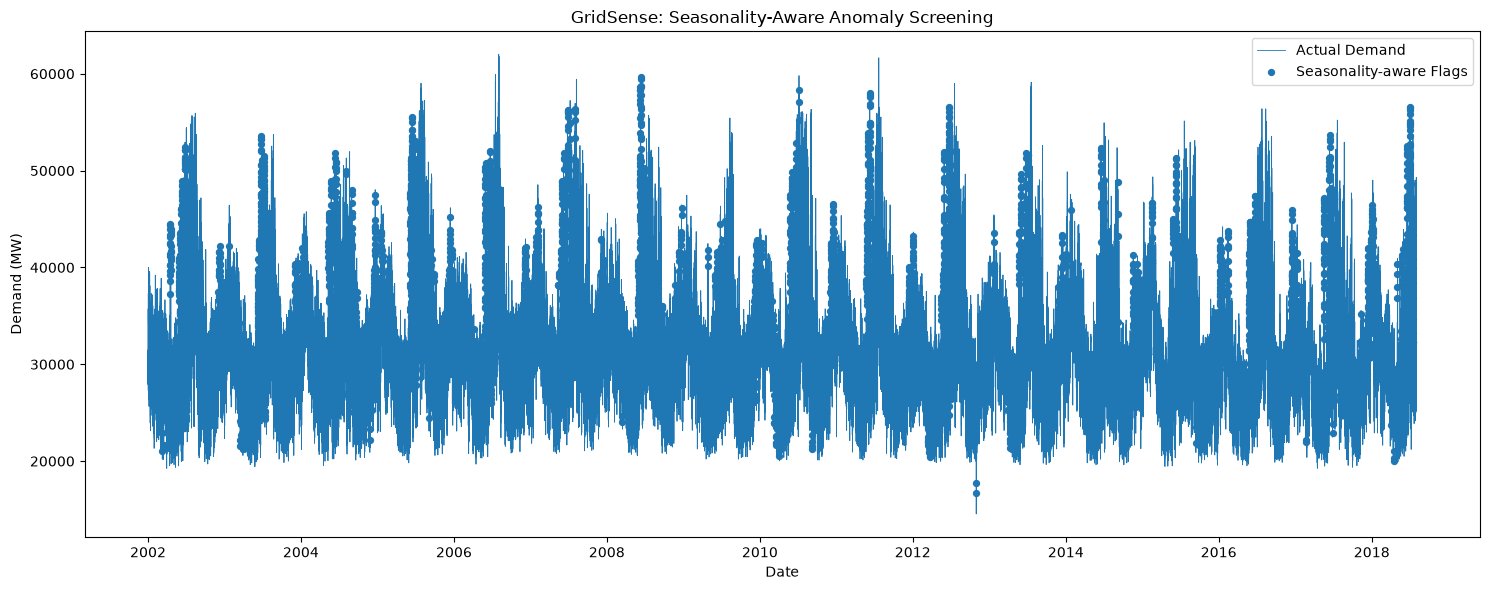

In [7]:
plt.figure(figsize=(15, 6))

plt.plot(
    analysis_df["Datetime"],
    analysis_df["PJME_MW"],
    label="Actual Demand",
    linewidth=0.6
)

seasonal_anomalies = analysis_df[
    analysis_df["Seasonal_Potential_Anomaly"]
]

plt.scatter(
    seasonal_anomalies["Datetime"],
    seasonal_anomalies["PJME_MW"],
    label="Seasonality-aware Flags",
    s=18
)

plt.title("GridSense: Seasonality-Aware Anomaly Screening")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
OUTPUT_PATH = Path("../data/processed")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

analysis_df.to_csv(
    OUTPUT_PATH / "anomaly_detection_results.csv",
    index=False
)

print("Saved to:", OUTPUT_PATH / "anomaly_detection_results.csv")

Saved to: ..\data\processed\anomaly_detection_results.csv


In [9]:
print("Total observations:", len(analysis_df))

print("\nSimple detector:")
print(analysis_df["Anomaly_Score"].describe())

print("\nSeasonality-aware detector:")
print(analysis_df["Seasonal_Anomaly_Score"].describe())

print("\nSeasonal MAD:")
print(analysis_df["Seasonal_MAD"].describe())

print("\nMissing seasonal scores:",
      analysis_df["Seasonal_Anomaly_Score"].isna().sum())

Total observations: 145366

Simple detector:
count    145318.000000
mean          0.987338
std           1.091839
min           0.000000
25%           0.311583
50%           0.691705
75%           1.257865
max          21.453699
Name: Anomaly_Score, dtype: float64

Seasonality-aware detector:
count    144022.000000
mean          1.016998
std           1.338814
min           0.000000
25%           0.275873
50%           0.635366
75%           1.258705
max          37.268058
Name: Seasonal_Anomaly_Score, dtype: float64

Seasonal MAD:
count    144022.000000
mean       3220.318333
std        1839.444637
min         187.500000
25%        1930.250000
50%        2788.000000
75%        4015.500000
max       14160.250000
Name: Seasonal_MAD, dtype: float64

Missing seasonal scores: 1344


In [10]:
print("Top seasonal anomaly scores:")

display(
    analysis_df.nlargest(
        10, "Seasonal_Anomaly_Score"
    )[
        [
            "Datetime",
            "PJME_MW",
            "Seasonal_Baseline",
            "Seasonal_Deviation",
            "Seasonal_MAD",
            "Seasonal_Anomaly_Score"
        ]
    ]
)

Top seasonal anomaly scores:


,Datetime,PJME_MW,Seasonal_Baseline,Seasonal_Deviation,Seasonal_MAD,Seasonal_Anomaly_Score
12955,2003-06-24 23:00:00,39502.0,28064.5,11437.5,207.00,37.268058
126232,2016-05-27 19:00:00,43406.0,28758.5,14647.5,289.25,34.155932
38644,2006-05-30 14:00:00,48354.0,31680.0,16674.0,337.00,33.372282
38647,2006-05-30 17:00:00,50415.0,31385.5,19029.5,401.50,31.968174
56520,2008-06-13 14:00:00,47002.0,32869.0,14133.0,309.25,30.824827
13123,2003-07-01 23:00:00,37304.0,28064.5,9239.5,207.00,30.106074
69816,2009-12-19 17:00:00,40377.0,28893.0,11484.0,265.25,29.202081
135408,2017-06-14 03:00:00,32207.0,21346.5,10860.5,254.00,28.839791
12999,2003-06-26 19:00:00,52141.0,31083.5,21057.5,493.25,28.794910
39151,2006-06-20 17:00:00,47627.0,31785.0,15842.0,401.50,26.613406


In [11]:
# Calculate historical deviation from weekday-hour baseline
analysis_df["Hour"] = analysis_df["Datetime"].dt.hour
analysis_df["DayOfWeek"] = analysis_df["Datetime"].dt.dayofweek

grouped = analysis_df.groupby(["DayOfWeek", "Hour"])["PJME_MW"]

# Previous 8 matching weekday-hour observations
analysis_df["Seasonal_Baseline"] = grouped.transform(
    lambda s: s.shift(1).rolling(8, min_periods=4).median()
)

analysis_df["Seasonal_Deviation"] = (
    analysis_df["PJME_MW"] - analysis_df["Seasonal_Baseline"]
)

# Historical absolute deviations from the same seasonal baseline
analysis_df["Seasonal_Abs_Deviation"] = (
    analysis_df["Seasonal_Deviation"].abs()
)

analysis_df["Seasonal_MAD"] = (
    analysis_df.groupby(["DayOfWeek", "Hour"])["Seasonal_Abs_Deviation"]
    .transform(lambda s: s.shift(1).rolling(8, min_periods=4).median())
)

scale = 1.4826 * analysis_df["Seasonal_MAD"]

# Avoid unstable scores when historical variation is zero or tiny
minimum_scale = analysis_df["PJME_MW"].median() * 0.005
scale = scale.clip(lower=minimum_scale)

analysis_df["Seasonal_Anomaly_Score"] = (
    analysis_df["Seasonal_Deviation"].abs() / scale
)

analysis_df["Seasonal_Potential_Anomaly"] = (
    analysis_df["Seasonal_Anomaly_Score"] > 3.5
)

print(
    "Revised potential anomalies:",
    int(analysis_df["Seasonal_Potential_Anomaly"].sum())
)

Revised potential anomalies: 6048


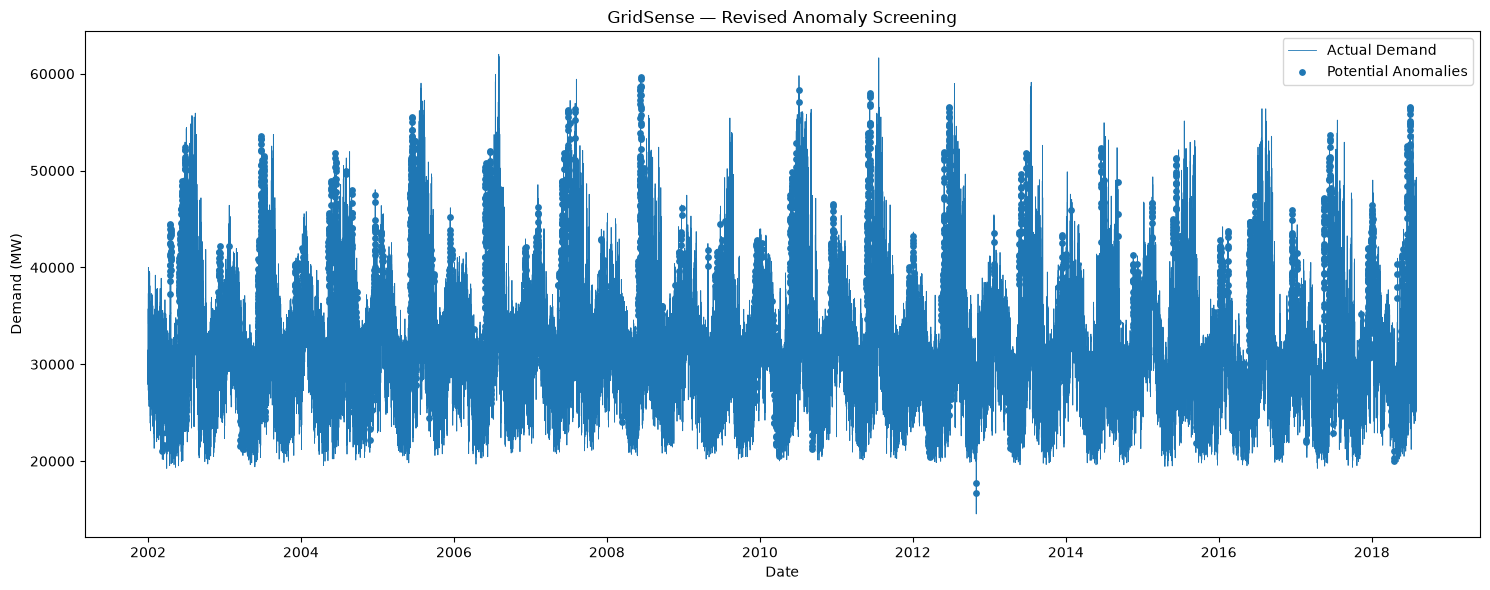

In [12]:
plt.figure(figsize=(15, 6))

plt.plot(
    analysis_df["Datetime"],
    analysis_df["PJME_MW"],
    label="Actual Demand",
    linewidth=0.6
)

flags = analysis_df[analysis_df["Seasonal_Potential_Anomaly"]]

plt.scatter(
    flags["Datetime"],
    flags["PJME_MW"],
    label="Potential Anomalies",
    s=15
)

plt.title("GridSense — Revised Anomaly Screening")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
from pathlib import Path

output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)

analysis_df.to_csv(
    output_path / "anomaly_detection_results.csv",
    index=False
)

print("Anomaly results saved successfully!")

Anomaly results saved successfully!
